# Best fitted line

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

In [2]:
dat = np.array([
    [100, 89, 89, 92, 78, 101, 90, 82, 95, 108, 111, 112, 125, 123, 100, 102, 112, 112, 100, 107, 103, 129, 118, 149],
    [709, 740, 586, 806, 694, 760, 664, 509, 619, 652, 772, 896, 742, 831, 667, 772, 838, 679, 889, 690, 698, 860, 799, 882]]).T

dat = dat/10

In [3]:
n = len(dat)
Y = dat[:,1]
X = np.vstack([np.ones(n), dat[:,0]]).T
p = X.shape[1]

## Computing the coefficients

Using the inverse

In [4]:
beta = np.linalg.inv(X.T @ X) @ X.T @ Y
beta

array([33.48189264,  3.84580363])

Using solve

In [5]:
beta = np.linalg.solve(X.T @ X, X.T @ Y)
beta

array([33.48189264,  3.84580363])

Using the least squares procedure

In [6]:
beta = np.linalg.lstsq(X, Y, rcond=None)[0]
beta

array([33.48189264,  3.84580363])

## Calculating the SSE

By hand

In [7]:
Y_hat = X @ beta
SSE = sum((Y_hat-Y)**2)
SSE

np.float64(1426.4995982039989)

Using the least squares procesure

In [8]:
SSE = np.linalg.lstsq(X, Y, rcond=None)[1][0]
SSE

np.float64(1426.499598203998)

Computing confidence and prediction intervals

In [9]:
alpha = 0.05

x_grid = np.linspace(7, 15, 50)
X_grid = np.array([np.ones(len(x_grid)), x_grid]).T
Y_grid_hat = X_grid @ beta

In [10]:
# Computing confidence interval
aux_t_conf = np.sqrt(SSE/(n-p) * (np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
ci_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_conf
ci_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_conf

# Computing prediction interval
aux_t_pred = np.sqrt(SSE/(n-p) * (1 + np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
pi_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_pred
pi_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_pred

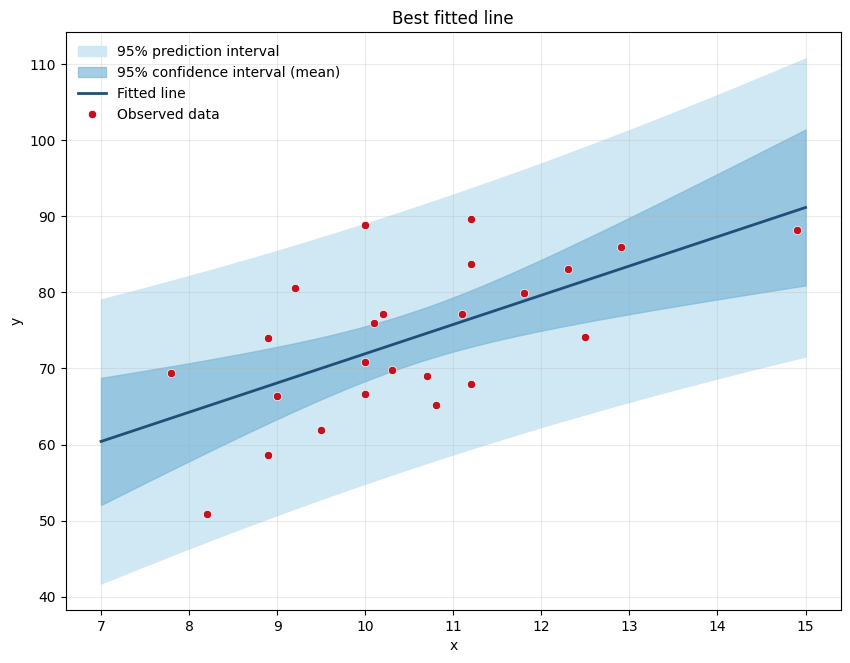

In [11]:
plt.figure(figsize=(10,7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(x_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(x_grid, ci_lower, ci_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(x_grid, beta[0] + beta[1]*x_grid, color='#1f4e79', lw=2, label='Fitted line')

# Observed data on top, dark and distinct
plt.plot(dat[:,0], Y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Best fitted line')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)